# Measuring nonlinear dependence with information

Mutual information measures how much knowing either variable reduces uncertainty about the other:

$$
I(X;Y)=\sum_{x,y}p(x,y)\log\frac{p(x,y)}{p(x)p(y)}
=H(X)+H(Y)-H(X,Y).
$$

Here, $X$ and $Y$ are discretized random variables; $x$ and $y$ are possible values. $p(x,y)$ is their joint probability; $p(x),p(y)$ are marginal probabilities; $H$ denotes entropy; $\log$ uses one fixed base.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as ss
from IPython.display import Image
from sklearn.metrics import mutual_info_score

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.data.distance import distance_correlation, ksg_mutual_information
from RiskLabAI.data.distance.distance_metric import calculate_distance, calculate_mutual_information, calculate_number_of_bins, calculate_variation_of_information, calculate_variation_of_information_extended
from RiskLabAI.features.entropy_features import grassberger_entropy, miller_madow_entropy, nsb_entropy
from RiskLabAI.features.entropy_features.kontoyiannis import kontoyiannis_entropy
from RiskLabAI.features.entropy_features.lempel_ziv import lempel_ziv_entropy
from RiskLabAI.features.entropy_features.plug_in import plug_in_entropy_estimator
from RiskLabAI.features.entropy_features.pmf import probability_mass_function
from RiskLabAI.features.entropy_features.shannon import shannon_entropy

FIGURES = ROOT / "outputs" / "figures" / "09_dependence_geometry_information"
TABLES = ROOT / "outputs" / "tables" / "09_dependence_geometry_information"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

raw = raw.sort_values("time").dropna(subset=["time", "close"]).drop_duplicates("time").reset_index(drop=True)
minute_close = pd.Series(raw["close"].to_numpy(dtype=float), index=pd.DatetimeIndex(raw["time"]), name="One-minute close")
close = minute_close.resample("15min").last().dropna().rename("Fifteen-minute close")
log_price = np.log(close).rename("Log price")
returns = log_price.diff().dropna().rename("Fifteen-minute log return")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Separating shared information from remaining variation

Variation of information adds what remains uncertain in each variable after the other is known, and normalization places the value between zero and one:

$$
\operatorname{VI}(X,Y)=H(X)+H(Y)-2I(X;Y),
\qquad
\widetilde{\operatorname{VI}}(X,Y)=\frac{\operatorname{VI}(X,Y)}{H(X,Y)}.
$$

Here, $H(X)$ and $H(Y)$ are marginal entropies; $H(X,Y)$ is joint entropy; $I(X;Y)$ is mutual information. $\operatorname{VI}(X,Y)$ is variation of information; $\widetilde{\operatorname{VI}}(X,Y)$ is its joint-entropy normalization.

In [2]:
pair_data = {
    "Return and one-step lag": (returns.iloc[1:].to_numpy(), returns.iloc[:-1].to_numpy()),
    "Return and absolute return": (returns.to_numpy(), np.abs(returns.to_numpy())),
    "Return and squared return": (returns.to_numpy(), returns.to_numpy() ** 2),
    "One- and four-interval returns": (pd.concat([log_price.diff(1), log_price.diff(4)], axis=1).dropna().iloc[:, 0].to_numpy(), pd.concat([log_price.diff(1), log_price.diff(4)], axis=1).dropna().iloc[:, 1].to_numpy()),
}
dependence_rows = []
identity_rows = []
for label, (x, y) in pair_data.items():
    correlation_value = np.corrcoef(x, y)[0, 1]
    bins = calculate_number_of_bins(len(x), correlation=correlation_value)
    normalized_mi = calculate_mutual_information(x, y, norm=True)
    normalized_vi = calculate_variation_of_information_extended(x, y, norm=True)
    counts = np.histogram2d(x, y, bins)[0]
    mutual_information = mutual_info_score(None, None, contingency=counts)
    entropy_x = ss.entropy(counts.sum(axis=1))
    entropy_y = ss.entropy(counts.sum(axis=0))
    joint_entropy = entropy_x + entropy_y - mutual_information
    variation_identity = entropy_x + entropy_y - 2 * mutual_information
    variation_released = calculate_variation_of_information(x, y, bins=bins, norm=False)
    dependence_rows.append({"Pair": label, "Observations": len(x), "Bins": bins, "Correlation": correlation_value, "Normalized mutual information": normalized_mi, "Normalized variation of information": normalized_vi})
    identity_rows.append({"Pair": label, "Mutual information": mutual_information, "Joint entropy": joint_entropy, "Variation from identity": variation_identity, "Released variation": variation_released, "Absolute difference": abs(variation_identity - variation_released)})
dependence_summary = pd.DataFrame(dependence_rows)
information_identity_checks = pd.DataFrame(identity_rows)
save_table(dependence_summary, "dependence_summary", "Linear and information-based dependence for public return pairs.", "tab:chapter8-dependence-summary", fit=True)
save_table(information_identity_checks, "information_identity_checks", "Independent checks of the variation-of-information identity.", "tab:chapter8-information-identity", fit=True)
display(dependence_summary.round(6))
display(information_identity_checks.round(12))

,Pair,Observations,Bins,Correlation,Normalized mutual information,Normalized variation of information
0,Return and one-step lag,2974,12,-0.023661,0.038134,0.980563
1,Return and absolute return,2975,12,0.061784,0.653331,0.610269
2,Return and squared return,2975,12,0.147051,0.793022,0.935375
3,One- and four-interval returns,2972,12,0.476218,0.124040,0.936150


,Pair,Mutual information,Joint entropy,Variation from identity,Released variation,Absolute difference
0,Return and one-step lag,0.039130,2.013101,1.973971,1.973971,0
1,Return and absolute return,0.504073,1.293387,0.789315,0.789315,0
2,Return and squared return,0.067437,1.043518,0.976081,0.976081,0
3,One- and four-interval returns,0.127328,1.994168,1.866840,1.866840,0


## Choosing Bins

The released rule chooses the same number of histogram bins for two continuous variables using sample size and their estimated correlation:

$$
B=\operatorname{round}\!\left[
\frac{1}{\sqrt{2}}
\sqrt{1+\sqrt{1+\frac{24N}{1-\widehat\rho^{\,2}}}}
\right].
$$

Here, $B$ is the chosen bin count; $N$ is the number of paired observations; $\widehat\rho$ is their sample correlation. $\operatorname{round}$ selects the nearest integer; the formula requires $|\widehat\rho|<1$ before numerical endpoint handling.

In [3]:
nonlinear_x, nonlinear_y = pair_data["Return and absolute return"]
lag_x, lag_y = pair_data["Return and one-step lag"]
sensitivity_rows = []
for bins in [4, 6, 8, 10, 12, 16, 20, 30, 40]:
    for label, x, y in [("Return and absolute return", nonlinear_x, nonlinear_y), ("Return and one-step lag", lag_x, lag_y)]:
        counts = np.histogram2d(x, y, bins)[0]
        mutual_information = mutual_info_score(None, None, contingency=counts)
        entropy_x = ss.entropy(counts.sum(axis=1))
        entropy_y = ss.entropy(counts.sum(axis=0))
        joint_entropy = entropy_x + entropy_y - mutual_information
        normalized_mi = mutual_information / min(entropy_x, entropy_y)
        normalized_vi = (entropy_x + entropy_y - 2 * mutual_information) / joint_entropy
        sensitivity_rows.append({"Pair": label, "Bins": bins, "Normalized mutual information": normalized_mi, "Normalized variation of information": normalized_vi})
information_bin_sensitivity = pd.DataFrame(sensitivity_rows)
save_table(information_bin_sensitivity, "information_bin_sensitivity", "Dependence estimates under several fixed bin counts.", "tab:chapter8-bin-sensitivity", fit=True)
display(information_bin_sensitivity.round(6))

,Pair,Bins,Normalized mutual information,Normalized variation of information
0,Return and absolute return,4,0.706926,0.671647
1,Return and one-step lag,4,0.056586,0.970883
2,Return and absolute return,6,0.538365,0.767438
3,Return and one-step lag,6,0.042398,0.978342
4,Return and absolute return,8,0.292740,0.886063
5,Return and one-step lag,8,0.020412,0.989689
6,Return and absolute return,10,0.370382,0.827265
7,Return and one-step lag,10,0.023014,0.988360
8,Return and absolute return,12,0.653331,0.610269
9,Return and one-step lag,12,0.038134,0.980563


## Known-Truth Information Tests

The first expression gives the exact information shared by two jointly normal variables, while the second estimates shared information from nearby observations:

$$
I_{\mathrm G}(\rho)=-\frac{1}{2}\log_2(1-\rho^2),
\qquad
\widehat I_{\mathrm{NN}}
=\psi(k)+\psi(N)-\frac{1}{N}\sum_{i=1}^{N}
\left[\psi(n_{x,i}+1)+\psi(n_{y,i}+1)\right].
$$

Here, $I_{\mathrm G}(\rho)$ is exact mutual information in bits; $\rho\in(-1,1)$ is correlation; $\log_2$ uses base two. $\widehat I_{\mathrm{NN}}$ is the nearest-neighbor estimate in natural-log units; $N$ is sample size; $k$ is the chosen neighbor count. $\psi$ is the digamma function; $n_{x,i}$ and $n_{y,i}$ count marginal neighbors around observation $i.$

Distance correlation compares centered pairwise distances and can detect both straight and curved dependence:

$$
\operatorname{dCor}(X,Y)
=\sqrt{\frac{\overline{AB}}{\sqrt{\overline{A^2}\,\overline{B^2}}}}.
$$

Here, $X$ and $Y$ are paired variables; $A$ and $B$ are their double-centered distance matrices. $\overline{AB}$ is the mean entrywise product; $\overline{A^2}$ and $\overline{B^2}$ are mean squared entries; $\operatorname{dCor}\in[0,1].$

,Relation,Sample size,Method,True information in bits,Mean estimate in bits,Estimate standard deviation,Root mean squared error
0,Straight Gaussian relation,200,Nearest-neighbor estimate,0.485715,0.483928,0.088082,0.085114
1,Straight Gaussian relation,200,Binned estimate,0.485715,0.512171,0.050305,0.055333
2,Straight Gaussian relation,1000,Nearest-neighbor estimate,0.485715,0.507397,0.041000,0.045156
3,Straight Gaussian relation,1000,Binned estimate,0.485715,0.488876,0.034752,0.033722
4,Monotone cubic relation,1000,Nearest-neighbor estimate,0.485715,0.444286,0.039018,0.056012
5,Monotone cubic relation,1000,Binned estimate,0.485715,0.274170,0.057165,0.218635


,Relation,Pearson correlation,Distance correlation,Nearest-neighbor information in bits
0,Independent,0.002572,0.075667,-0.017118
1,Straight,0.717683,0.669806,0.499713
2,Curved,0.023679,0.540144,2.585016


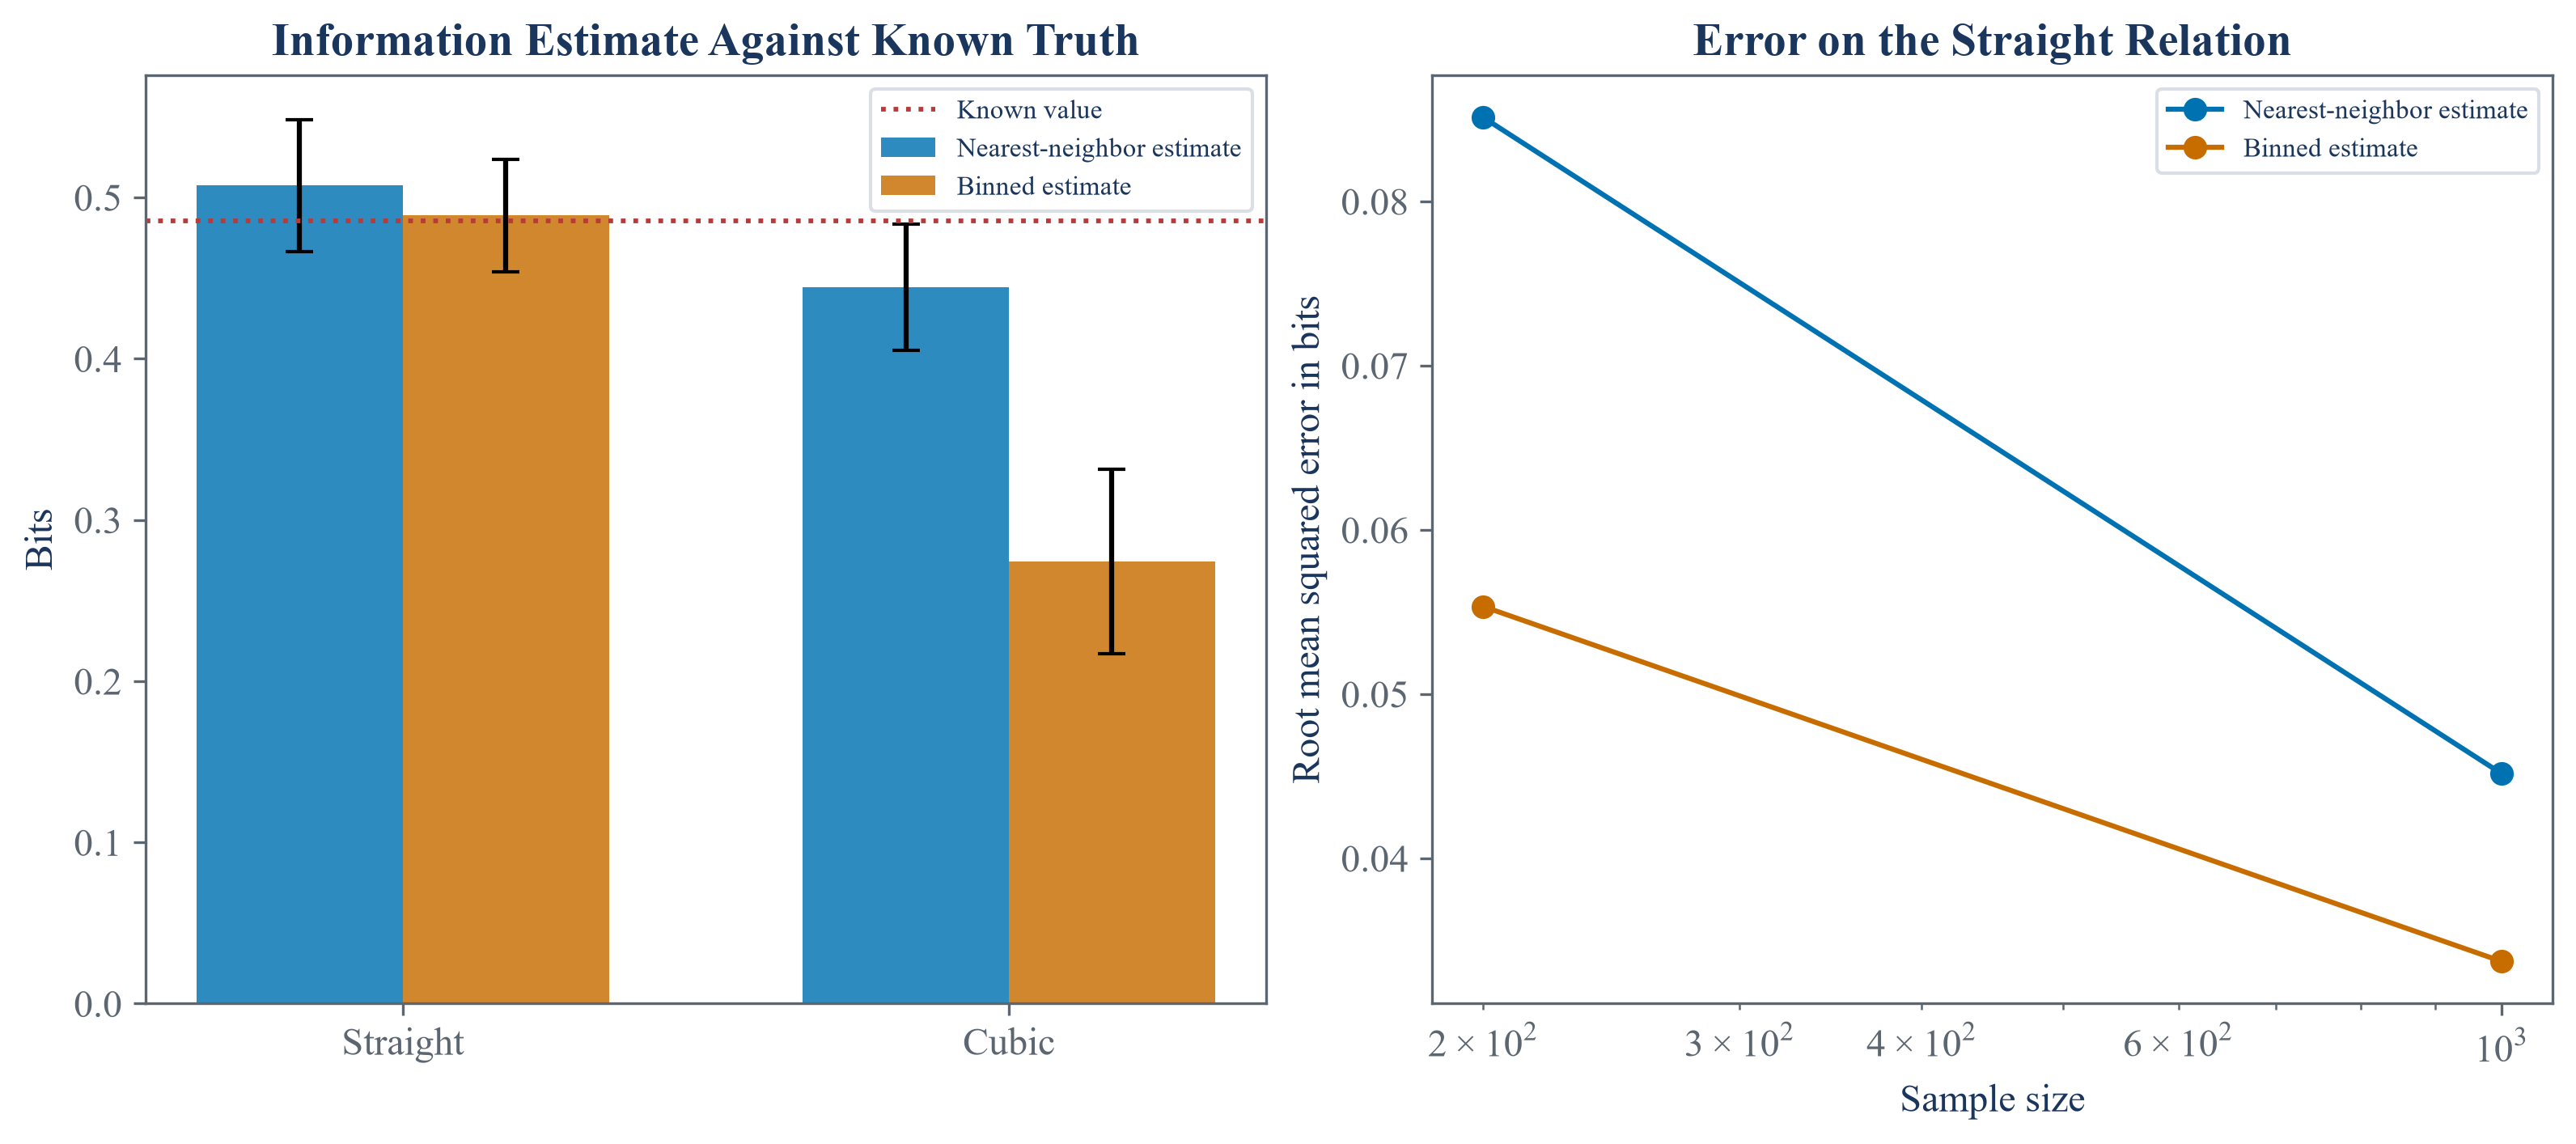

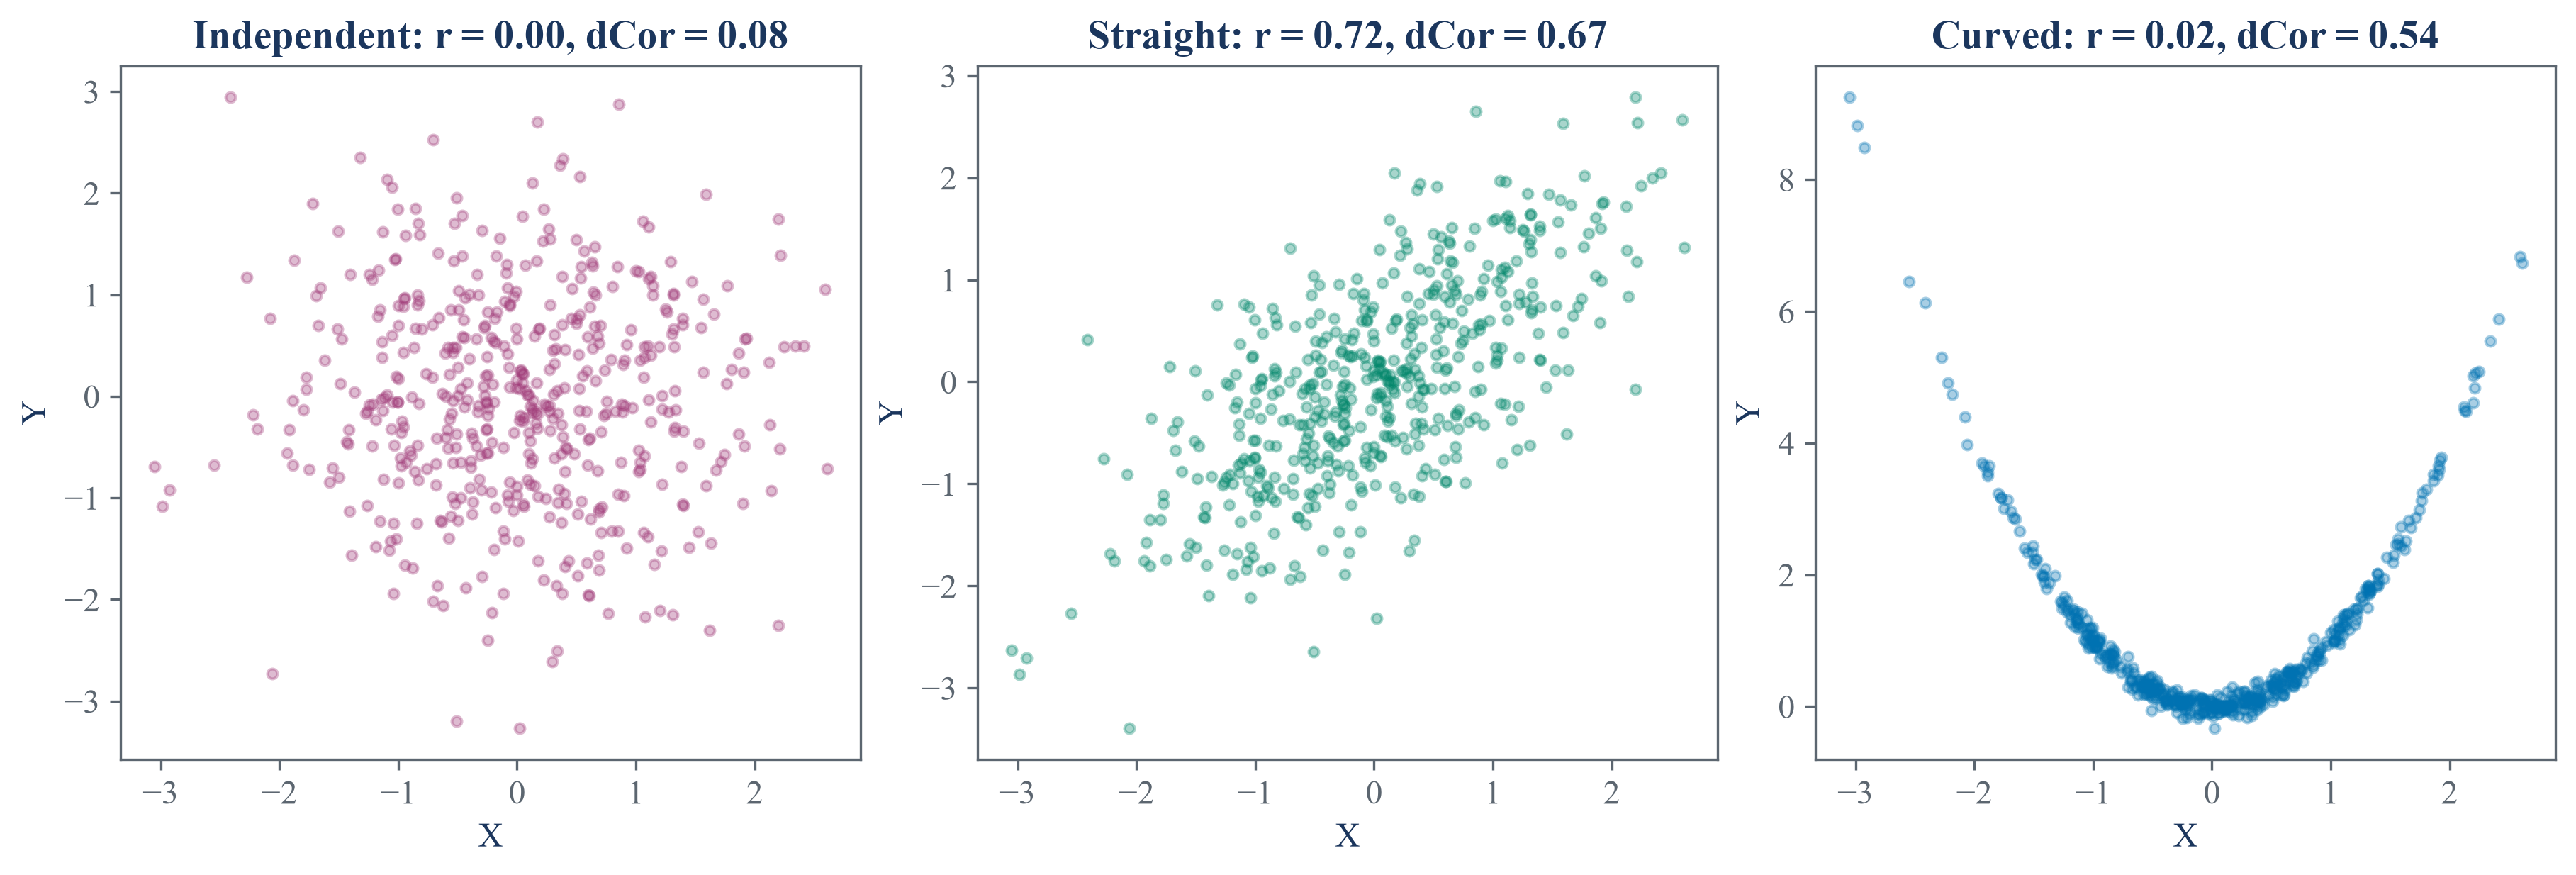

In [4]:
log_two = np.log(2.0)

def gaussian_information_bits(correlation_value):
    return -0.5 * np.log(1.0 - correlation_value ** 2) / log_two

known_correlation = 0.70
true_information = gaussian_information_bits(known_correlation)
information_runs = []
stored_information = {}
for relation, sample_size in [("Straight Gaussian relation", 200), ("Straight Gaussian relation", 1000), ("Monotone cubic relation", 1000)]:
    nearest_values = []
    binned_values = []
    for seed in range(15):
        random_generator = np.random.default_rng(seed)
        common_driver = random_generator.standard_normal(sample_size)
        if relation == "Straight Gaussian relation":
            x_values = common_driver
            y_values = known_correlation * common_driver + np.sqrt(1.0 - known_correlation ** 2) * random_generator.standard_normal(sample_size)
        else:
            x_values = known_correlation * common_driver + np.sqrt(1.0 - known_correlation ** 2) * random_generator.standard_normal(sample_size)
            y_values = common_driver ** 3
        nearest_values.append(ksg_mutual_information(x_values, y_values, k=4, random_state=seed) / log_two)
        binned_values.append(calculate_mutual_information(x_values, y_values) / log_two)
    for method, values in [("Nearest-neighbor estimate", np.asarray(nearest_values)), ("Binned estimate", np.asarray(binned_values))]:
        stored_information[(relation, sample_size, method)] = values
        information_runs.append({"Relation": relation, "Sample size": sample_size, "Method": method, "True information in bits": true_information, "Mean estimate in bits": values.mean(), "Estimate standard deviation": values.std(ddof=1), "Root mean squared error": np.sqrt(np.mean((values - true_information) ** 2))})
known_truth_information_summary = pd.DataFrame(information_runs)

screen_rows = []
screen_samples = {}
for relation in ["Independent", "Straight", "Curved"]:
    for seed in range(5):
        random_generator = np.random.default_rng(8100 + 10 * seed)
        x_values = random_generator.standard_normal(500)
        if relation == "Independent":
            y_values = random_generator.standard_normal(500)
        elif relation == "Straight":
            y_values = 0.7 * x_values + np.sqrt(1.0 - 0.49) * random_generator.standard_normal(500)
        else:
            y_values = x_values ** 2 + 0.1 * random_generator.standard_normal(500)
        if seed == 0:
            screen_samples[relation] = (x_values, y_values)
        screen_rows.append({"Relation": relation, "Seed": seed, "Pearson correlation": np.corrcoef(x_values, y_values)[0, 1], "Distance correlation": distance_correlation(x_values, y_values), "Nearest-neighbor information in bits": ksg_mutual_information(x_values, y_values, random_state=seed) / log_two})
nonlinear_screen_runs = pd.DataFrame(screen_rows)
nonlinear_screen_summary = nonlinear_screen_runs.groupby("Relation", sort=False).agg({"Pearson correlation": "mean", "Distance correlation": "mean", "Nearest-neighbor information in bits": "mean"}).reset_index()
save_table(known_truth_information_summary, "known_truth_information_summary", "Known-truth information estimates over fifteen fixed seeds.", "tab:chapter8-known-truth-information", fit=True)
save_table(nonlinear_screen_summary, "nonlinear_screen_summary", "Linear and nonlinear dependence measures for three controlled relations.", "tab:chapter8-nonlinear-screen", fit=True)
display(known_truth_information_summary.round(6))
display(nonlinear_screen_summary.round(6))

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), constrained_layout=True)
benchmark_cases = [("Straight Gaussian relation", 1000), ("Monotone cubic relation", 1000)]
method_names = ["Nearest-neighbor estimate", "Binned estimate"]
method_colors = [palette["cyan"], palette["amber"]]
positions = np.arange(len(benchmark_cases))
width = 0.34
for method_position, (method, color) in enumerate(zip(method_names, method_colors)):
    means = [stored_information[(relation, size, method)].mean() for relation, size in benchmark_cases]
    errors = [stored_information[(relation, size, method)].std(ddof=1) for relation, size in benchmark_cases]
    axes[0].bar(positions + (method_position - 0.5) * width, means, width=width, yerr=errors, capsize=4, color=color, alpha=0.82, label=method)
axes[0].axhline(true_information, color=palette["rose"], linestyle=":", linewidth=1.4, label="Known value")
axes[0].set_xticks(positions, ["Straight", "Cubic"])
axes[0].set_title("Information Estimate Against Known Truth")
axes[0].set_ylabel("Bits")
axes[0].legend(fontsize=8)
for method, color in zip(method_names, method_colors):
    current = known_truth_information_summary[(known_truth_information_summary["Relation"] == "Straight Gaussian relation") & (known_truth_information_summary["Method"] == method)]
    axes[1].plot(current["Sample size"], current["Root mean squared error"], marker="o", color=color, linewidth=1.5, label=method)
axes[1].set_xscale("log")
axes[1].set_title("Error on the Straight Relation")
axes[1].set_xlabel("Sample size")
axes[1].set_ylabel("Root mean squared error in bits")
axes[1].legend(fontsize=8)
figure.savefig(FIGURES / "known_truth_information.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "known_truth_information.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "known_truth_information.png")))
plt.close(figure)

figure, axes = plt.subplots(1, 3, figsize=(12.0, 4.0), constrained_layout=True)
for axis, relation, color in zip(axes, ["Independent", "Straight", "Curved"], [palette["violet"], palette["green"], palette["cyan"]]):
    x_values, y_values = screen_samples[relation]
    summary_row = nonlinear_screen_summary[nonlinear_screen_summary["Relation"] == relation].iloc[0]
    axis.scatter(x_values, y_values, s=11, alpha=0.34, color=color)
    axis.set_title(f"{relation}: r = {summary_row['Pearson correlation']:.2f}, dCor = {summary_row['Distance correlation']:.2f}")
    axis.set_xlabel("X")
    axis.set_ylabel("Y")
figure.savefig(FIGURES / "controlled_dependence_cases.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "controlled_dependence_cases.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "controlled_dependence_cases.png")))
plt.close(figure)

## A Public Nonlinear Example

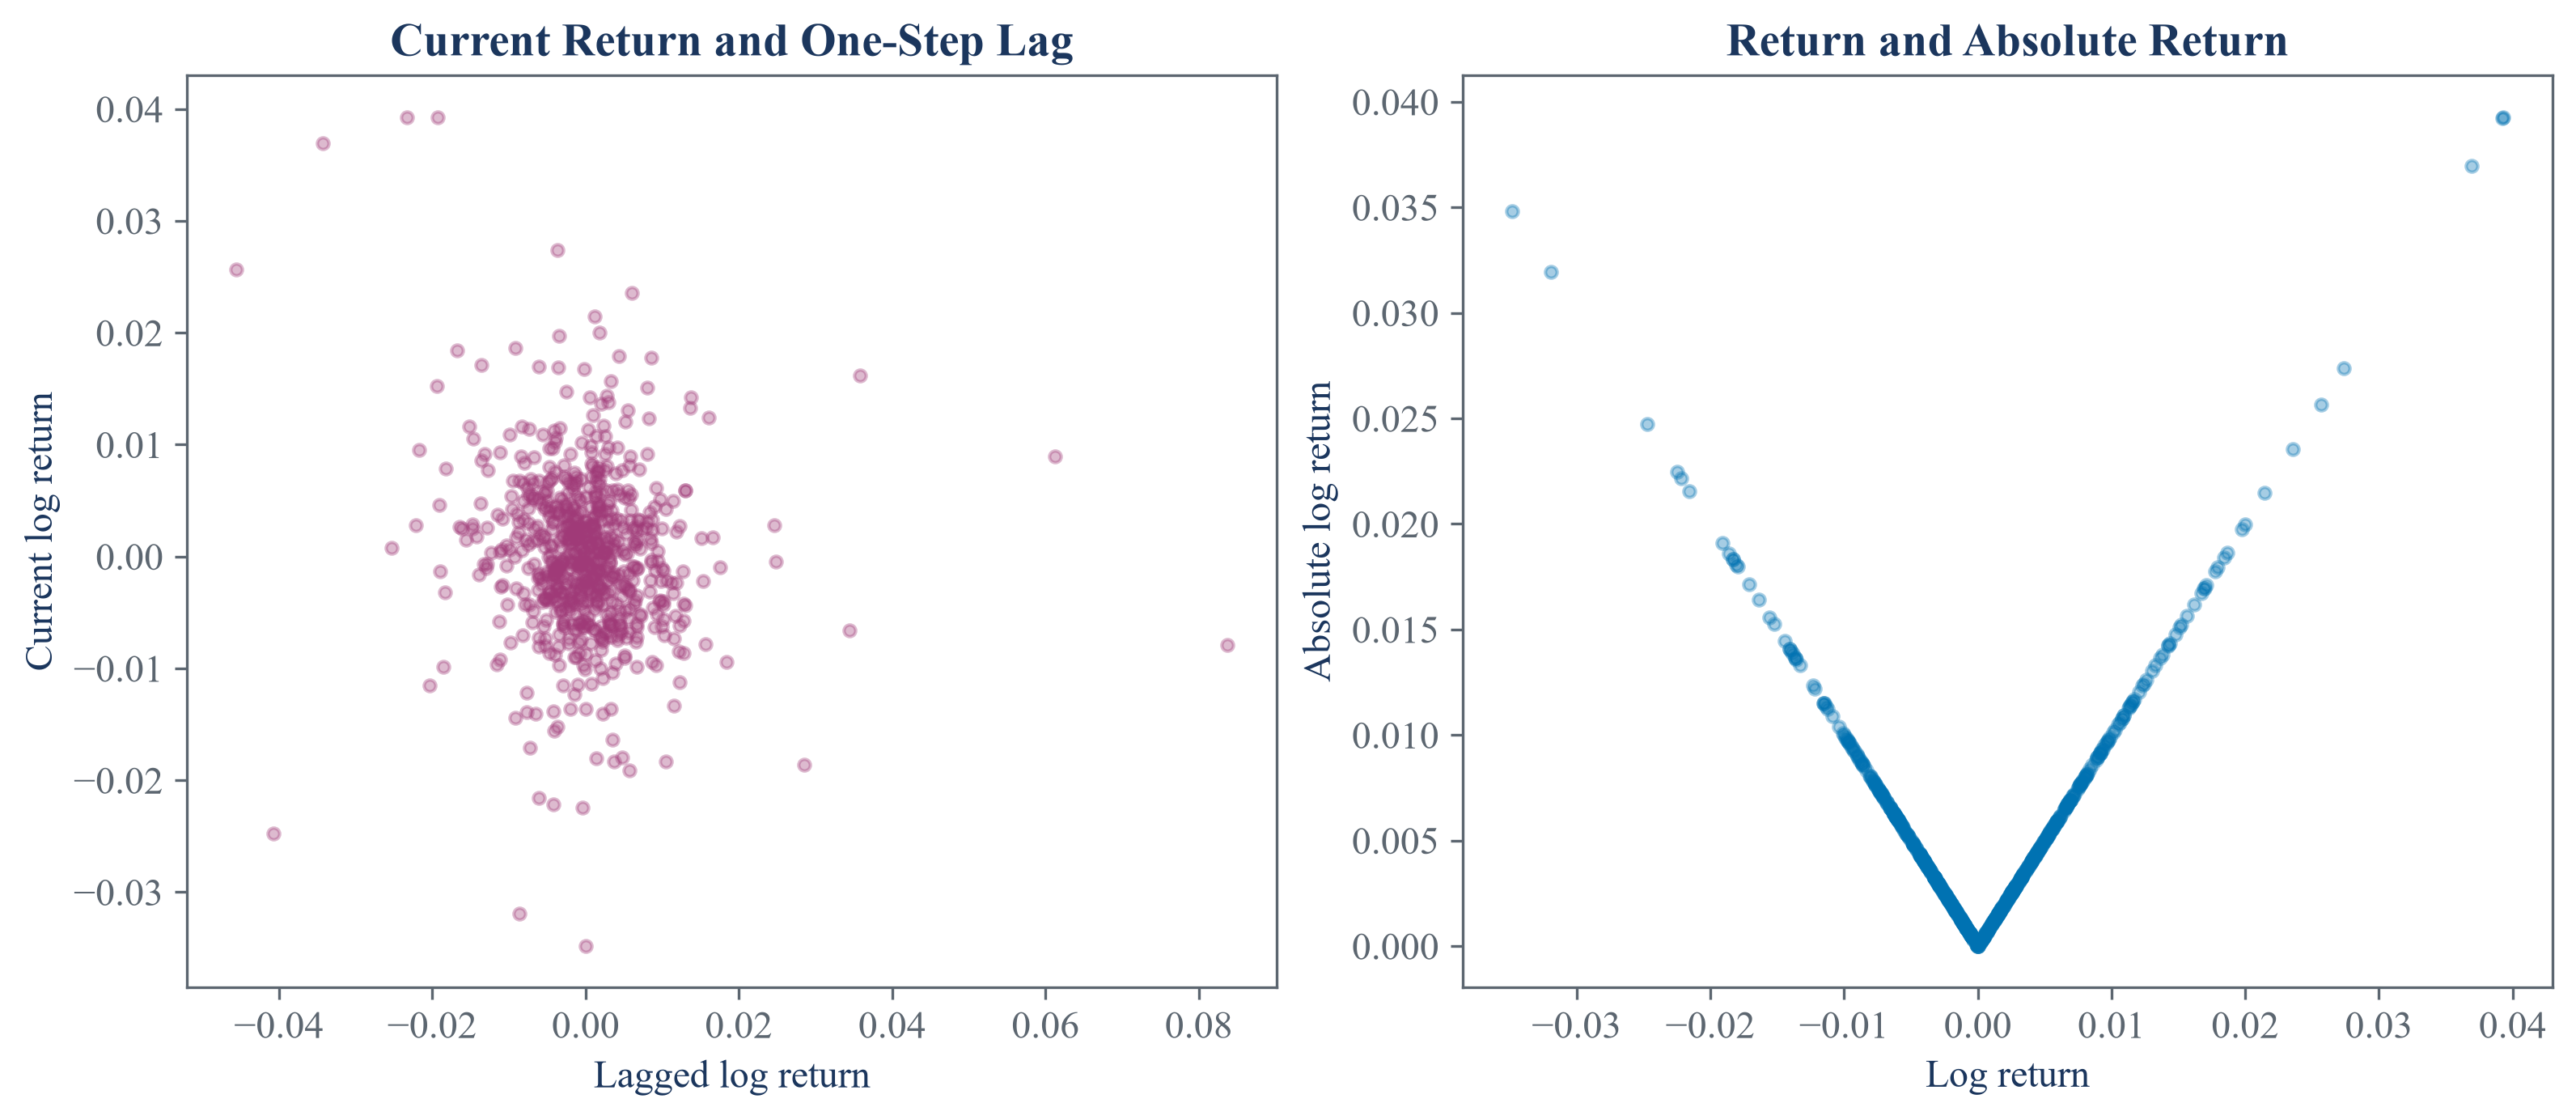

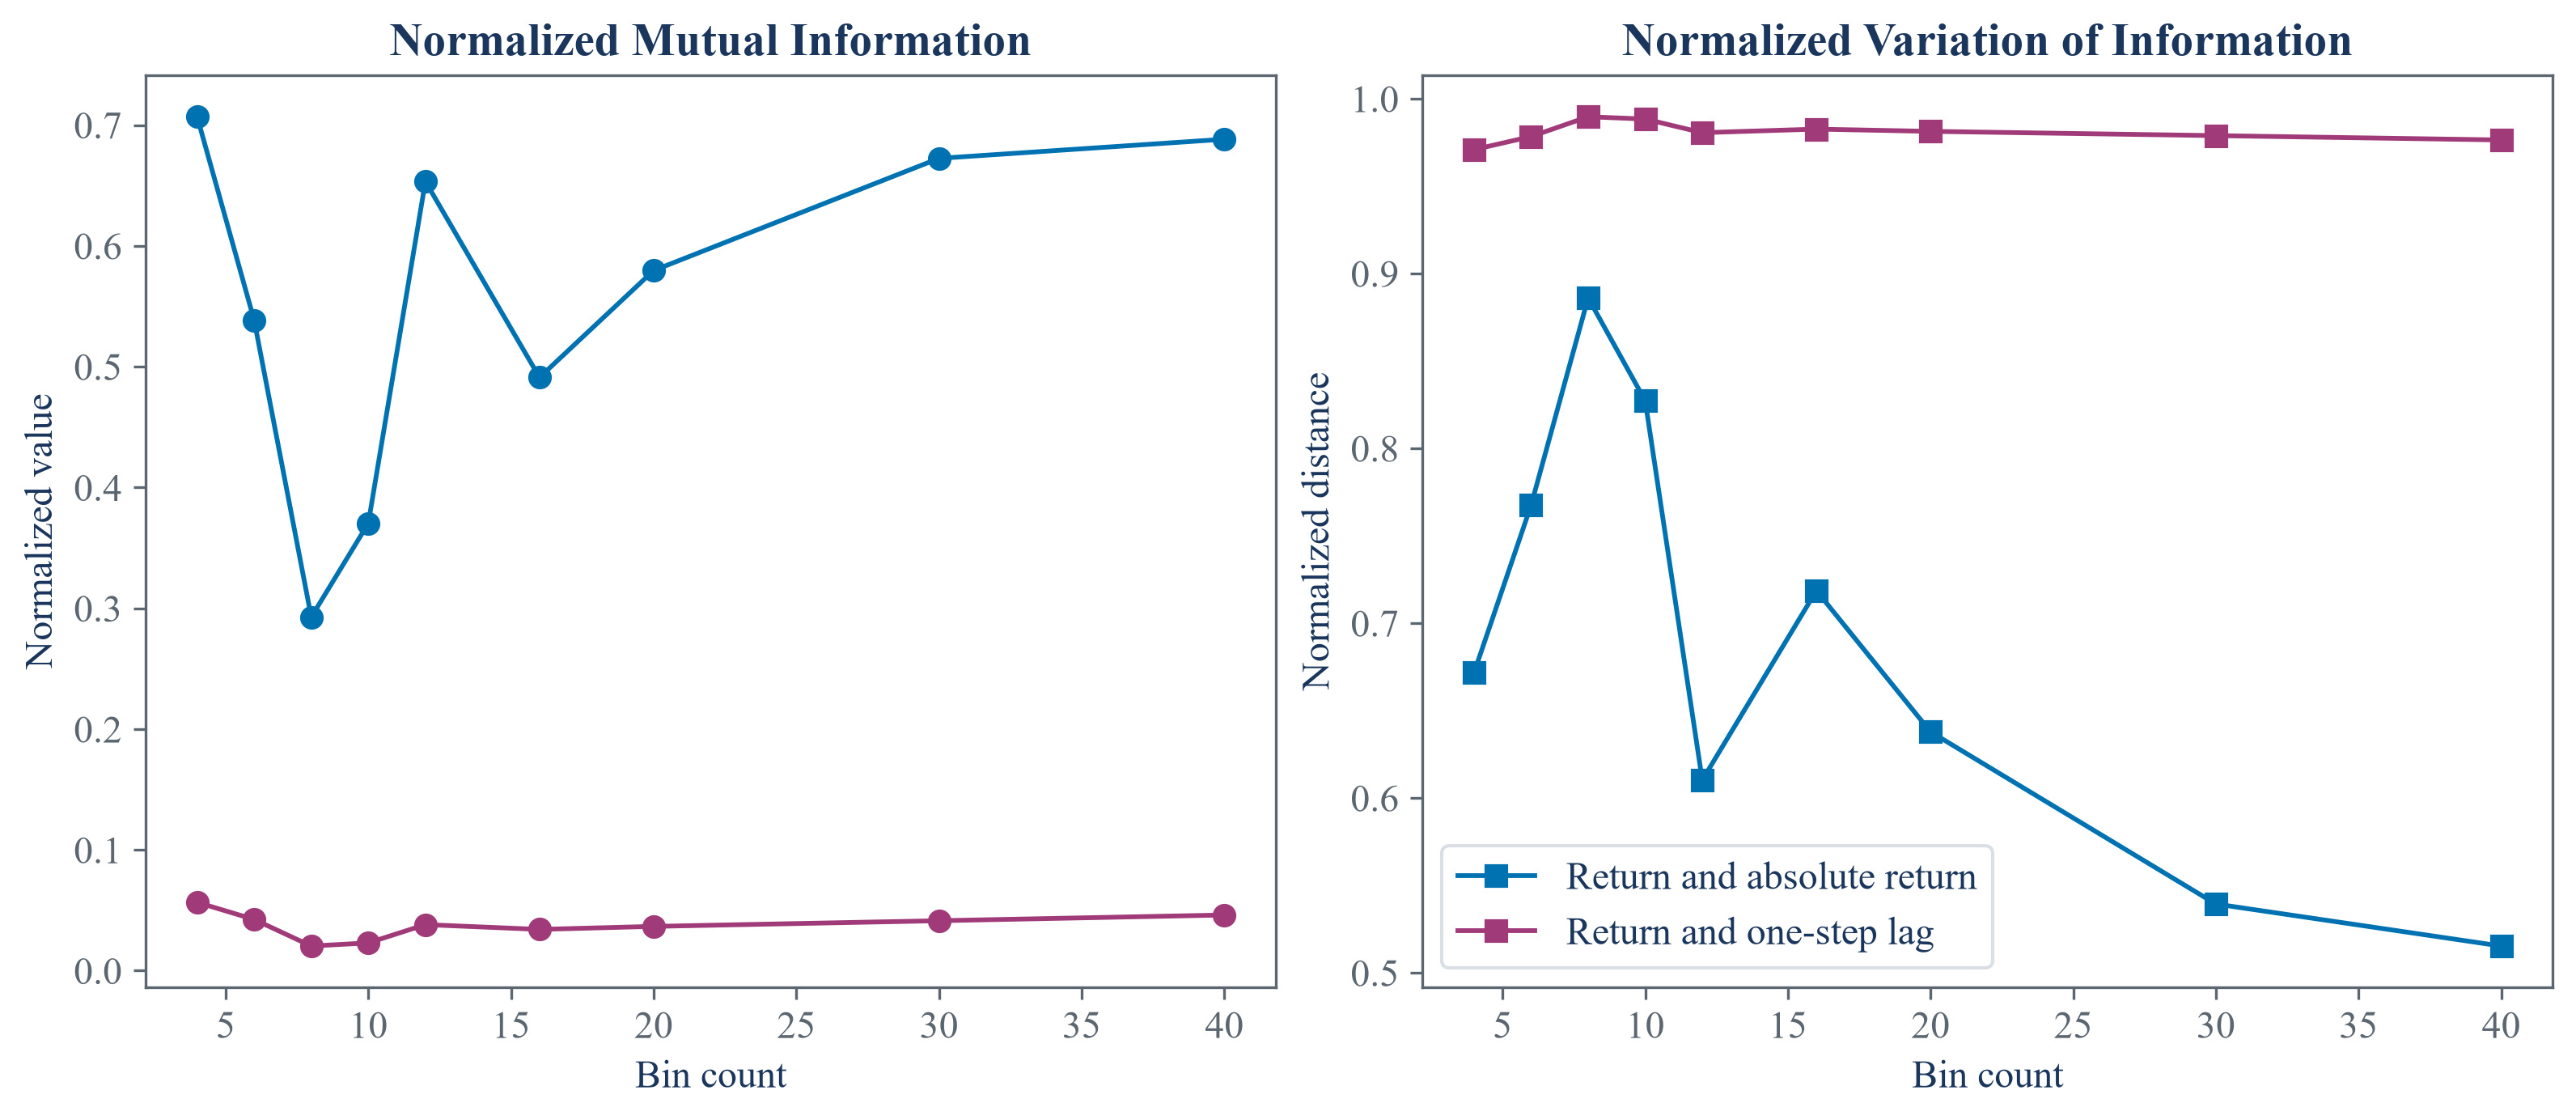

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), constrained_layout=True)
sample_positions = np.linspace(1, len(returns) - 1, 700, dtype=int)
sampled_returns = returns.iloc[sample_positions]
axes[0].scatter(returns.shift(1).iloc[sample_positions], sampled_returns, s=12, alpha=0.35, color=palette["violet"])
axes[0].set_title("Current Return and One-Step Lag")
axes[0].set_xlabel("Lagged log return")
axes[0].set_ylabel("Current log return")
axes[1].scatter(sampled_returns, np.abs(sampled_returns), s=12, alpha=0.35, color=palette["cyan"])
axes[1].set_title("Return and Absolute Return")
axes[1].set_xlabel("Log return")
axes[1].set_ylabel("Absolute log return")
figure.savefig(FIGURES / "public_dependence_scatter.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_dependence_scatter.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_dependence_scatter.png")))
plt.close(figure)

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), constrained_layout=True)
colors = {"Return and absolute return": palette["cyan"], "Return and one-step lag": palette["violet"]}
for label, group in information_bin_sensitivity.groupby("Pair"):
    axes[0].plot(group["Bins"], group["Normalized mutual information"], marker="o", linewidth=1.4, color=colors[label], label=label)
    axes[1].plot(group["Bins"], group["Normalized variation of information"], marker="s", linewidth=1.4, color=colors[label], label=label)
axes[0].set_title("Normalized Mutual Information")
axes[0].set_xlabel("Bin count")
axes[0].set_ylabel("Normalized value")
axes[1].set_title("Normalized Variation of Information")
axes[1].set_xlabel("Bin count")
axes[1].set_ylabel("Normalized distance")
axes[1].legend()
figure.savefig(FIGURES / "information_bin_sensitivity.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "information_bin_sensitivity.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "information_bin_sensitivity.png")))
plt.close(figure)

## Tests

In [6]:
nonlinear_row = dependence_summary.loc[dependence_summary["Pair"] == "Return and absolute return"].iloc[0]
lag_row = dependence_summary.loc[dependence_summary["Pair"] == "Return and one-step lag"].iloc[0]
toy_x = np.array([1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3])
toy_y = np.array([1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3])
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert len(dependence_summary) == 4
assert len(information_bin_sensitivity) == 18
assert information_identity_checks["Absolute difference"].max() < 1e-12
assert abs(nonlinear_row["Correlation"]) < 0.15
assert nonlinear_row["Normalized mutual information"] > lag_row["Normalized mutual information"]
assert nonlinear_row["Normalized variation of information"] < lag_row["Normalized variation of information"]
assert 0.0 <= nonlinear_row["Normalized mutual information"] <= 1.0
assert 0.0 <= nonlinear_row["Normalized variation of information"] <= 1.0
assert np.isclose(calculate_mutual_information(toy_x, toy_x, norm=True), 1.0)
assert np.isclose(calculate_variation_of_information(toy_x, toy_x, bins=3, norm=True), 0.0)
assert np.isclose(calculate_mutual_information(toy_x, toy_y, norm=True), 0.0, atol=0.1)
assert calculate_number_of_bins(len(nonlinear_x), correlation=np.corrcoef(nonlinear_x, nonlinear_y)[0, 1]) == int(nonlinear_row["Bins"])
assert information_bin_sensitivity.groupby("Pair").size().eq(9).all()
cubic_nearest_error = known_truth_information_summary.query("Relation == 'Monotone cubic relation' and Method == 'Nearest-neighbor estimate'")["Root mean squared error"].iloc[0]
cubic_binned_error = known_truth_information_summary.query("Relation == 'Monotone cubic relation' and Method == 'Binned estimate'")["Root mean squared error"].iloc[0]
curved_screen = nonlinear_screen_summary[nonlinear_screen_summary["Relation"] == "Curved"].iloc[0]
independent_screen = nonlinear_screen_summary[nonlinear_screen_summary["Relation"] == "Independent"].iloc[0]
assert cubic_nearest_error < cubic_binned_error
assert curved_screen["Distance correlation"] > abs(curved_screen["Pearson correlation"])
assert curved_screen["Nearest-neighbor information in bits"] > independent_screen["Nearest-neighbor information in bits"]
assert independent_screen["Distance correlation"] < 0.15
assert (FIGURES / "public_dependence_scatter.pdf").is_file()
assert (FIGURES / "information_bin_sensitivity.pdf").is_file()
assert (FIGURES / "known_truth_information.pdf").is_file()
assert (FIGURES / "controlled_dependence_cases.pdf").is_file()
assert (TABLES / "known_truth_information_summary.tex").is_file()
assert (TABLES / "nonlinear_screen_summary.tex").is_file()